# Supplementary analyses and figures for the revised manuscript
Colab version of `extra_analysis.py`. Produces `figures/*.png` and `tables/*.csv` (saved to Drive, and shown inline).

**Before running:** run `meta_analysis_colab.ipynb` first so that `output/meta_results.json` exists, and make sure `data/meta_estimates_203.csv` and `data/review_sample_257.csv` are in the same Drive folder.

The original script re-used the data prep and helper functions of `meta_analysis.py` via `exec(...)`; here they are inlined in section 2.

## 1. Setup (mount Drive, folders)

In [7]:
from google.colab import drive
drive.mount('/content/drive')
import os

# Project folder in Google Drive (change if you like). Both notebooks share it,
# so output/meta_results.json written by notebook 1 is visible to notebook 2.
ROOT = '/content/drive/MyDrive/green_finance_meta'
for sub in ['data', 'output', 'figures', 'tables']:
    os.makedirs(f'{ROOT}/{sub}', exist_ok=True)
os.chdir(ROOT)

needed = ['output/meta_results.json']
missing = [f for f in needed if not os.path.exists(f)]
print('Working directory:', os.getcwd())
print('Missing files:', missing if missing else 'none')

for f in ['data/meta_estimates_203.csv','data/review_sample_257.csv']:
    print(f, 'OK' if os.path.exists(f) else 'MISSING')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/drive/MyDrive/green_finance_meta
Missing files: ['output/meta_results.json']
data/meta_estimates_203.csv MISSING
data/review_sample_257.csv MISSING


## 2. Imports, data preparation and helper functions (from `meta_analysis.py`)

In [8]:
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy import stats, optimize
import statsmodels.api as sm
import statsmodels.formula.api as smf
import json
%matplotlib inline

In [11]:
import pandas as pd,numpy as np,json,os,statsmodels.api as sm,statsmodels.formula.api as smf
from scipy import stats,optimize
os.makedirs('output',exist_ok=True)
e=pd.read_csv('/content/meta_estimates_203.csv')
d=e.rename(columns={'study_id':'study','TCI_adjusted_pct':'TCI','TCI_reported_pct':'TCI_pct','tail_quantile':'tail'}).copy()
d['G']=d.Green_asset_class; d['R']=d.Region; d['M']=d.Method_family.replace({'BK-frequency':'DY-rolling','Other':'DY-rolling','QVAR-frequency':'QVAR','TVP-VAR-BK':'TVP-VAR'})
d['Freq_band']=d.Freq_band.fillna('Full'); d['vol']=(d.Connectedness_type=='Volatility').astype(int); d['hm']=(d.Connectedness_type=='Higher-moment').astype(int)
d['log_n']=np.log(d.n_vars); d['crisis']=(d.Crisis_subsample.fillna('None')!='None').astype(int)
d['weak']=d.Value_source.isin(['Figure-read','Computed','Text']).astype(int)
d['TCI']=d.TCI.clip(upper=100)            # adjusted TCI cannot exceed 100 (Qiao et al. 2024 reported value exceeds (N-1)/N)
def _ym(s):
    import re
    if pd.isna(s): return np.nan
    m=re.match(r'(\d{4})(?:-(\d{2}))?',str(s)); return int(m.group(1))+((int(m.group(2))-1)/12 if m.group(2) else 0.5)
d['y1']=d.Sample_end.map(_ym)
B=d[d.baseline].copy()

inv=lambda x:100/(1+np.exp(-x))
def prep(X,s=1):
    p=(X.TCI/100).clip(0.005,0.995); y=np.log(p/(1-p)); v=1/((X.T_use/s)*p*(1-p)); return np.asarray(y,float),np.asarray(v,float)
def dl(y,v):
    w=1/v;k=len(y);yb=np.sum(w*y)/np.sum(w);Q=np.sum(w*(y-yb)**2);df=k-1
    C=np.sum(w)-np.sum(w**2)/np.sum(w);t2=max(0,(Q-df)/C) if k>1 else 0
    wr=1/(v+t2);mu=np.sum(wr*y)/np.sum(wr);se=np.sqrt(1/np.sum(wr));I2=max(0,(Q-df)/Q)*100 if Q>0 else 0
    tcrit=stats.t.ppf(0.975,max(k-2,1)); pi=(mu-tcrit*np.sqrt(t2+se**2),mu+tcrit*np.sqrt(t2+se**2))
    return dict(k=k,Q=Q,df=df,p=stats.chi2.sf(Q,df) if df>0 else np.nan,I2=I2,t2=t2,mu=mu,se=se,lo=mu-1.96*se,hi=mu+1.96*se,pilo=pi[0],pihi=pi[1])
def tau2_reml(y,v):
    def nll(t2):
        w=1/(v+t2); mu=np.sum(w*y)/np.sum(w); return 0.5*(np.sum(np.log(v+t2))+np.log(np.sum(w))+np.sum(w*(y-mu)**2))
    return float(optimize.minimize_scalar(nll,bounds=(0,20),method='bounded',options={'xatol':1e-8}).x)
def tau2_pm(y,v):
    f=lambda t2:np.sum((1/(v+t2))*(y-np.sum(y/(v+t2))/np.sum(1/(v+t2)))**2)-(len(y)-1)
    return optimize.brentq(f,0,50) if f(0)>0 else 0.0
def re(y,v,method='REML'):
    """Random-effects pooling. Wald CI, Hartung-Knapp (modified, q>=1) CI, and prediction interval (t_{k-2})."""
    k=len(y); base=dl(y,v)
    t2={'REML':tau2_reml,'PM':tau2_pm,'DL':lambda a,b:dl(a,b)['t2']}[method](y,v) if k>1 else 0.0
    w=1/(v+t2); mu=np.sum(w*y)/np.sum(w); se=np.sqrt(1/np.sum(w))
    q=np.sum(w*(y-mu)**2)/(k-1) if k>1 else 1.0; se_hk=np.sqrt(max(q,1.0)/np.sum(w))
    tk=stats.t.ppf(0.975,max(k-1,1)); tp=stats.t.ppf(0.975,max(k-2,1))
    return dict(k=k,Q=base['Q'],df=base['df'],p=base['p'],I2=base['I2'],t2=t2,mu=mu,se=se,lo=mu-1.96*se,hi=mu+1.96*se,
                hklo=mu-tk*se_hk,hkhi=mu+tk*se_hk,pilo=mu-tp*np.sqrt(t2+se**2),pihi=mu+tp*np.sqrt(t2+se**2))
def mreg(y,v,X):
    # mixed-effects meta-regression, MM tau2, modified Knapp-Hartung
    X=np.asarray(X,float); k,p=X.shape; W=np.diag(1/v)
    XtWX=X.T@W@X; b=np.linalg.solve(XtWX,X.T@W@y); e_=y-X@b; QE=float(e_@W@e_)
    P=W-W@X@np.linalg.solve(XtWX,X.T@W); t2=max(0,(QE-(k-p))/np.trace(P))
    Ws=np.diag(1/(v+t2)); A=X.T@Ws@X; b=np.linalg.solve(A,X.T@Ws@y); e_=y-X@b
    s2=float(e_@Ws@e_)/(k-p); cov=np.linalg.inv(A)*max(s2,1); se=np.sqrt(np.diag(cov))
    return b,se,t2,QE,k-p,cov
def pooled_rows(df,agg='mean'):
    g=df.groupby('study').agg(TCI=('TCI','mean'),T_use=('T_use','first')).reset_index(); return prep(g)

## 3. Plot style, class labels and market-state coding

In [12]:
plt.rcParams.update({'font.family':'serif','font.size':9,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':150,'savefig.dpi':300})
CL={'CleanEnergy':'Clean energy','Carbon':'Carbon','GreenBond':'Green bonds','ESG/Sustainability':'ESG / sustainability','GreenCrypto':'Green crypto'}
order=['Clean energy','Carbon','Green bonds','ESG / sustainability','Green crypto']
d['Class']=d.G.map(CL)
def state(r):
    if r.Freq_band=='Short': return 'Short band'
    if r.Freq_band=='Long' or r.Freq_band=='Medium': return 'Long/med. band'
    if r['tail']==1: return 'Lower tail' if r.Quantile<=0.10 else 'Upper tail'
    if r.Quantile==0.5: return 'Median (τ=0.5)'
    return 'Full-sample (mean)'
d['State']=d.apply(state,axis=1)
states=['Full-sample (mean)','Median (τ=0.5)','Lower tail','Upper tail','Short band','Long/med. band']

## 4. Figures and tables

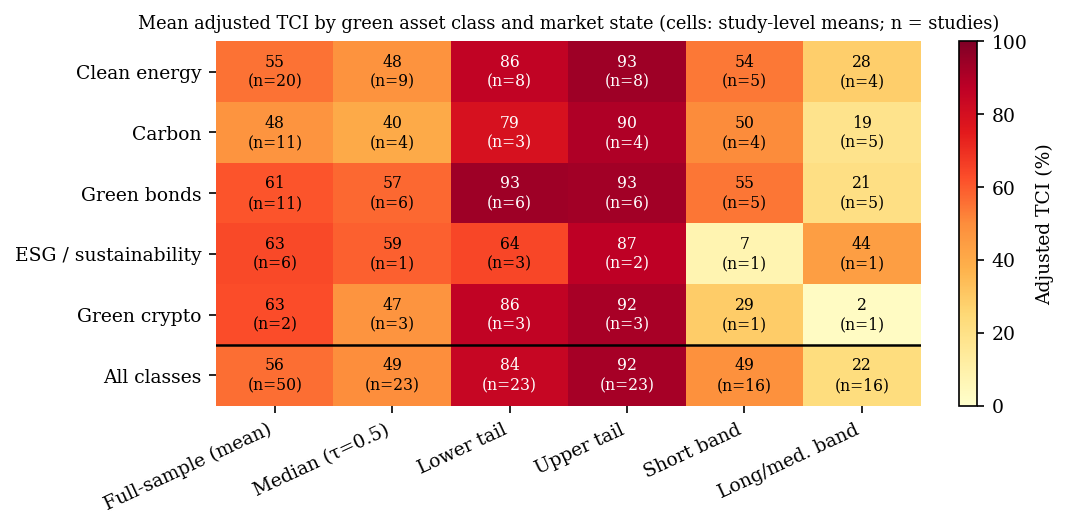

In [13]:
# ---------- Fig 7: heatmap asset class x state (study-averaged adjusted TCI)
g=d.groupby(['Class','State','study']).TCI.mean().reset_index()
M=g.groupby(['Class','State']).TCI.mean().unstack().reindex(index=order,columns=states)
N=g.groupby(['Class','State']).study.nunique().unstack().reindex(index=order,columns=states)
allr=g.groupby('State').TCI.mean().reindex(states); alln=g.groupby('State').study.nunique().reindex(states)
M.loc['All classes']=allr; N.loc['All classes']=alln
M.round(1).to_csv('tables/T_heatmap_class_by_state_mean.csv'); N.to_csv('tables/T_heatmap_class_by_state_n.csv')
fig,ax=plt.subplots(figsize=(7.2,3.6)); im=ax.imshow(M.values,cmap='YlOrRd',vmin=0,vmax=100,aspect='auto')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v=M.values[i,j]; n=N.values[i,j]
        t='–' if np.isnan(v) else f'{v:.0f}\n(n={int(n)})'
        ax.text(j,i,t,ha='center',va='center',fontsize=7.5,color='white' if (not np.isnan(v) and v>70) else 'black')
ax.set_xticks(range(len(states))); ax.set_xticklabels(states,rotation=25,ha='right'); ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
ax.axhline(4.5,color='k',lw=1.2); ax.spines[:].set_visible(False)
cb=plt.colorbar(im,ax=ax,fraction=0.03); cb.set_label('Adjusted TCI (%)')
ax.set_title('Mean adjusted TCI by green asset class and market state (cells: study-level means; n = studies)',fontsize=8.5)
plt.tight_layout(); plt.savefig('figures/Fig7_heatmap_class_by_state.png'); plt.show()

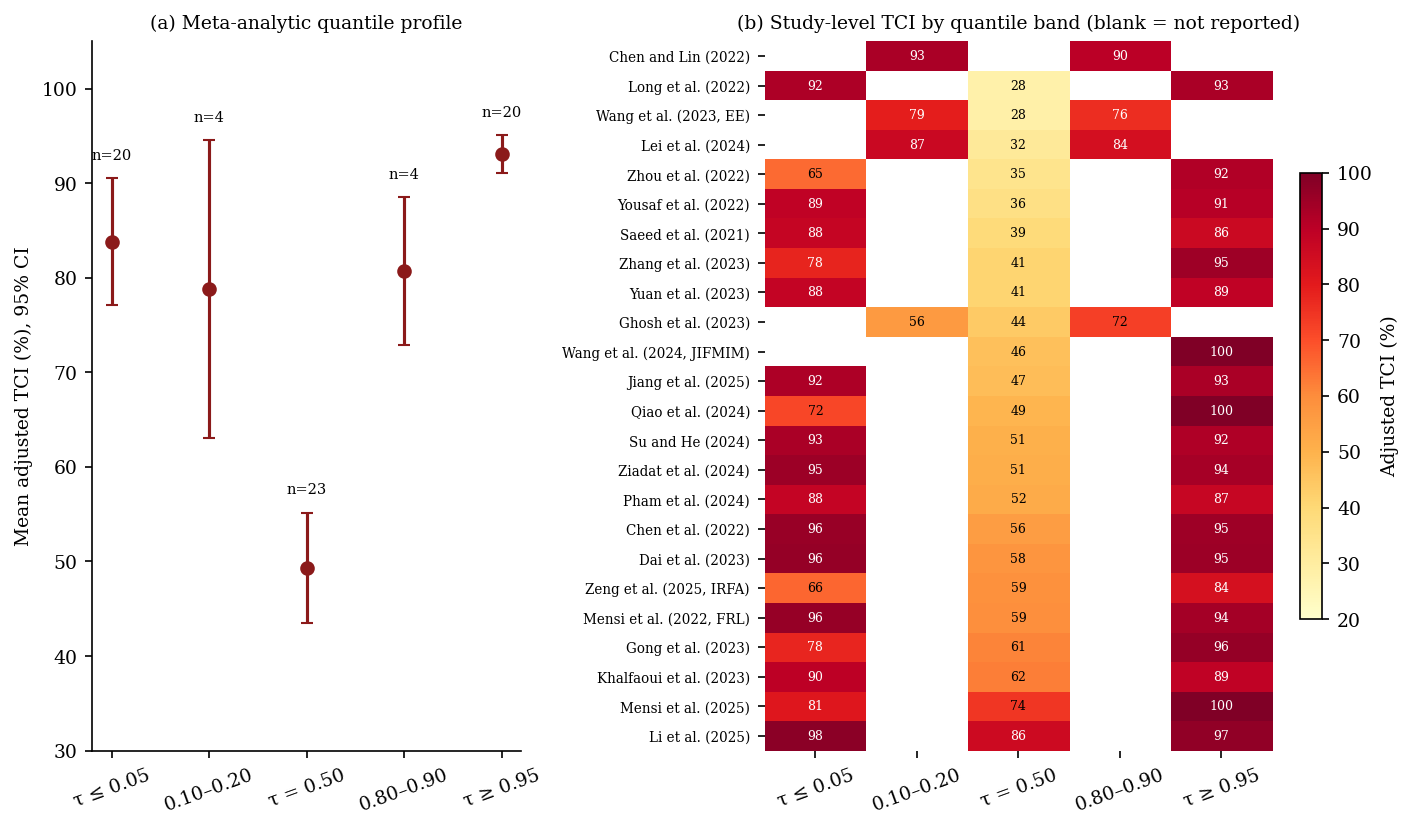

In [14]:
# ---------- Fig 8: quantile profile + study x tau-band heatmap
q=d[(d.Freq_band=='Full')&d.Quantile.notna()].copy()
bins=[(0,0.05,'τ ≤ 0.05'),(0.05,0.25,'0.10–0.20'),(0.25,0.75,'τ = 0.50'),(0.75,0.925,'0.80–0.90'),(0.925,1.01,'τ ≥ 0.95')]
def band(x):
    for lo_,hi_,l in bins:
        if lo_<x<=hi_ or (lo_==0 and x<=hi_): return l
q['Band']=q.Quantile.map(band); labs=[b_[2] for b_ in bins]
qs=q.groupby(['study','Band']).TCI.mean().reset_index()
prof=qs.groupby('Band').TCI.agg(['mean','count','std']).reindex(labs); prof['se']=prof['std']/np.sqrt(prof['count'])
prof.round(2).to_csv('tables/T_quantile_profile.csv')
P=qs.pivot(index='study',columns='Band',values='TCI').reindex(columns=labs)
lab=d.drop_duplicates('study').set_index('study')['Study (Author Year)']
P=P[P.notna().sum(axis=1)>=2]; P=P.sort_values(by='τ = 0.50',na_position='first'); P.index=[lab[i] for i in P.index]
fig,(a1,a2)=plt.subplots(1,2,figsize=(9.5,5.6),gridspec_kw={'width_ratios':[1,1.3]})
xs_=np.arange(len(labs)); a1.errorbar(xs_,prof['mean'],yerr=1.96*prof['se'],fmt='o',color='#8b1a1a',capsize=3,ms=6)
for x,yv,n,s_ in zip(xs_,prof['mean'],prof['count'],prof['se']): a1.text(x,yv+1.96*s_+2,f'n={int(n)}',ha='center',fontsize=7)
a1.set_xticks(xs_); a1.set_xticklabels(labs,rotation=20); a1.set_ylabel('Mean adjusted TCI (%), 95% CI'); a1.set_ylim(30,105); a1.set_title('(a) Meta-analytic quantile profile',fontsize=9)
im=a2.imshow(P.values,cmap='YlOrRd',vmin=20,vmax=100,aspect='auto')
for i in range(P.shape[0]):
    for j in range(P.shape[1]):
        if not np.isnan(P.values[i,j]): a2.text(j,i,f'{P.values[i,j]:.0f}',ha='center',va='center',fontsize=6,color='white' if P.values[i,j]>75 else 'black')
a2.set_xticks(range(len(labs))); a2.set_xticklabels(labs,rotation=20); a2.set_yticks(range(len(P))); a2.set_yticklabels(P.index,fontsize=6.5); a2.set_title('(b) Study-level TCI by quantile band (blank = not reported)',fontsize=9); a2.spines[:].set_visible(False)
plt.colorbar(im,ax=a2,fraction=0.04).set_label('Adjusted TCI (%)'); plt.tight_layout(); plt.savefig('figures/Fig8_quantile_profile_heatmap.png'); plt.show()

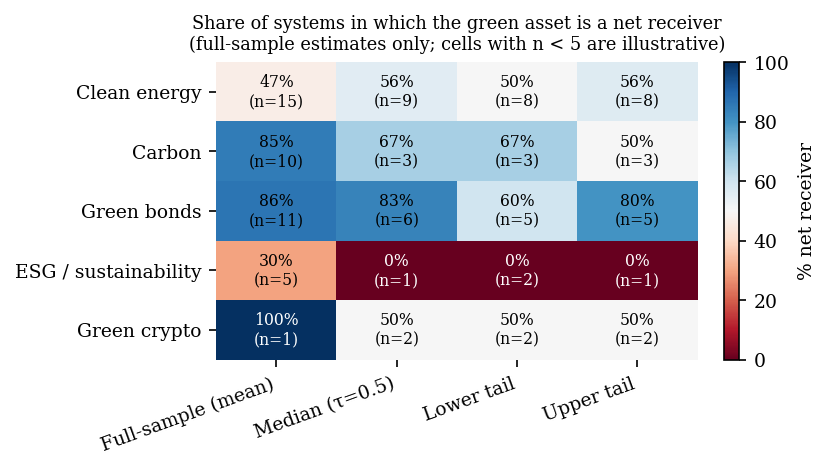

In [15]:
# ---------- Fig 9: net-role heatmap (share receivers) by class x state
rr=d[d.Green_net_role.isin(['Transmitter','Receiver'])&(d.Freq_band=='Full')].copy()
rs=rr.groupby(['Class','State','study']).Green_net_role.agg(lambda s:(s=='Receiver').mean()).reset_index()
R_=rs.groupby(['Class','State']).Green_net_role.mean().mul(100).unstack().reindex(index=order,columns=['Full-sample (mean)','Median (τ=0.5)','Lower tail','Upper tail'])
Rn=rs.groupby(['Class','State']).study.nunique().unstack().reindex(index=order,columns=R_.columns)
R_.round(0).to_csv('tables/T_receiver_share_class_by_state.csv'); Rn.to_csv('tables/T_receiver_share_n.csv')
fig,ax=plt.subplots(figsize=(5.6,3.2)); im=ax.imshow(R_.values,cmap='RdBu_r',vmin=0,vmax=100,aspect='auto')   # blue=receiver-dominant? (RdBu_r: high=red) -> invert labels
im.set_cmap('RdBu')
for i in range(R_.shape[0]):
    for j in range(R_.shape[1]):
        v=R_.values[i,j]; n=Rn.values[i,j]; ax.text(j,i,'–' if np.isnan(v) else f'{v:.0f}%\n(n={int(n)})',ha='center',va='center',fontsize=7.5,color='white' if (not np.isnan(v) and (v<15 or v>90)) else 'black')
ax.set_xticks(range(R_.shape[1])); ax.set_xticklabels(R_.columns,rotation=20,ha='right'); ax.set_yticks(range(5)); ax.set_yticklabels(order); ax.spines[:].set_visible(False)
cb=plt.colorbar(im,ax=ax,fraction=0.04); cb.set_label('% net receiver')
ax.set_title('Share of systems in which the green asset is a net receiver\n(full-sample estimates only; cells with n < 5 are illustrative)',fontsize=8.5); plt.tight_layout(); plt.savefig('figures/Fig9_heatmap_net_role.png'); plt.show()

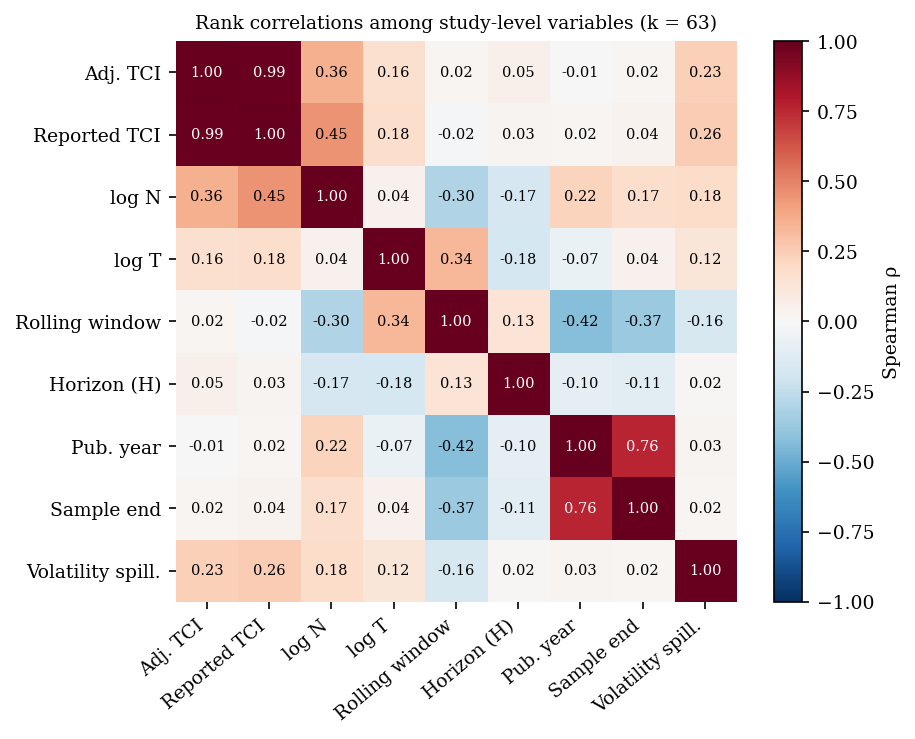

In [16]:
# ---------- Fig 10: Spearman heatmap among study-level variables (baseline)
Bx=B.copy(); Bx['logT']=np.log(Bx.T_use); Bx['volatility']=(Bx.Connectedness_type=='Volatility').astype(int)
Bx['log N']=np.log(Bx.n_vars); Bx['Adj. TCI']=Bx.TCI; Bx['Reported TCI']=Bx.TCI_pct; Bx['log T']=Bx.logT; Bx['Rolling window']=Bx.Window; Bx['Horizon (H)']=Bx.Horizon
Bx['Pub. year']=Bx.pubyear; Bx['Sample end']=Bx.y1; Bx['Volatility spill.']=Bx.volatility; Bx['Crisis subsample']=Bx.crisis
vars_=['Adj. TCI','Reported TCI','log N','log T','Rolling window','Horizon (H)','Pub. year','Sample end','Volatility spill.']
Cm=Bx[vars_].corr(method='spearman'); Cm.round(2).to_csv('tables/T_spearman_study_level.csv')
fig,ax=plt.subplots(figsize=(6.4,5.0)); im=ax.imshow(Cm.values,cmap='RdBu_r',vmin=-1,vmax=1)
for i in range(len(vars_)):
    for j in range(len(vars_)): ax.text(j,i,f'{Cm.values[i,j]:.2f}',ha='center',va='center',fontsize=7,color='white' if abs(Cm.values[i,j])>0.6 else 'black')
ax.set_xticks(range(len(vars_))); ax.set_xticklabels(vars_,rotation=40,ha='right'); ax.set_yticks(range(len(vars_))); ax.set_yticklabels(vars_)
plt.colorbar(im,ax=ax,fraction=0.045).set_label('Spearman ρ'); ax.set_title('Rank correlations among study-level variables (k = 63)',fontsize=9); ax.spines[:].set_visible(False)
plt.tight_layout(); plt.savefig('figures/Fig10_heatmap_moderator_correlations.png'); plt.show()

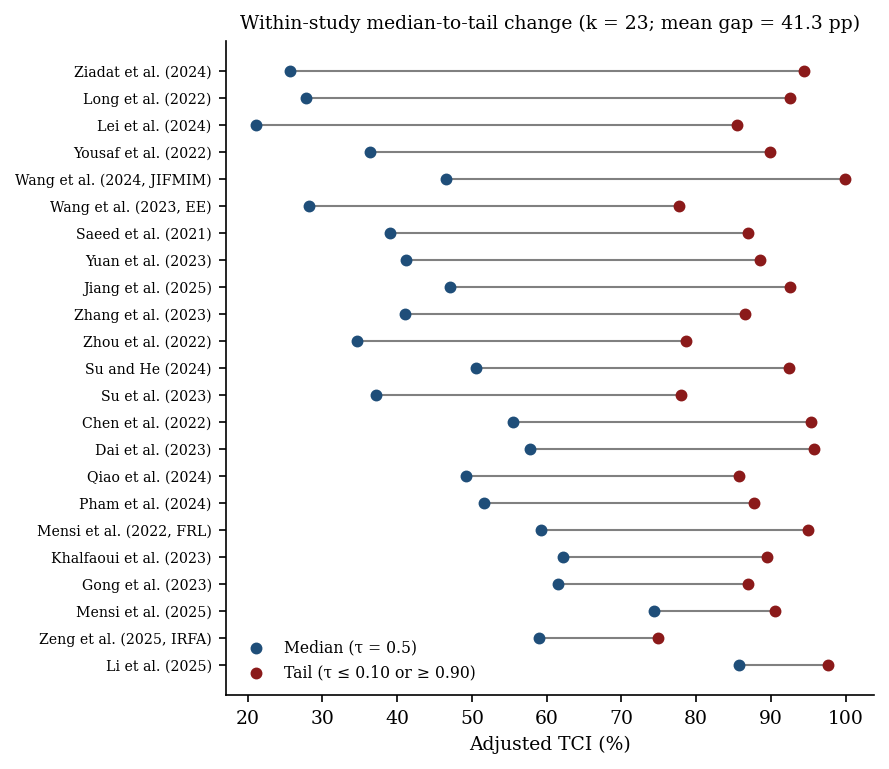

In [17]:
# ---------- Fig 11: within-study dumbbell median -> tail
med=d[d.Quantile==0.5]; tl=d[d['tail']==1]   # same definition as meta_analysis.py (within-study tail premium)
rows=[]
for s in sorted(set(med.study)&set(tl.study)):
    rows.append((lab[s],med[med.study==s].TCI.mean(),tl[tl.study==s].TCI.mean()))
W=pd.DataFrame(rows,columns=['study','median','tailv']); W['gap']=W['tailv']-W['median']; W=W.sort_values('gap'); W.round(1).to_csv('tables/T_within_study_gap.csv',index=False)
fig,ax=plt.subplots(figsize=(6,5.2))
for i,(s,m_,t_,g_) in enumerate(W[['study','median','tailv','gap']].itertuples(index=False)):
    ax.plot([m_,t_],[i,i],color='grey',lw=1);
ax.scatter(W['median'],range(len(W)),color='#1f4e79',label='Median (τ = 0.5)',zorder=3,s=22); ax.scatter(W['tailv'],range(len(W)),color='#8b1a1a',label='Tail (τ ≤ 0.10 or ≥ 0.90)',zorder=3,s=22)
ax.set_yticks(range(len(W))); ax.set_yticklabels(W.study,fontsize=6.8); ax.set_xlabel('Adjusted TCI (%)'); ax.legend(frameon=False,loc='lower left',fontsize=7.5)
ax.set_title(f'Within-study median-to-tail change (k = {len(W)}; mean gap = {W.gap.mean():.1f} pp)',fontsize=9); plt.tight_layout(); plt.savefig('figures/Fig11_within_study_tail_premium.png'); plt.show()

In [ ]:
# ---------- Fig 12: system size scatter w/ meta-regression line
y,v=prep(B); X=np.column_stack([np.ones(len(B)),np.log(B.n_vars)]); b,se,t2,QE,df,cov=mreg(y,v,X)
xs=np.linspace(np.log(2),np.log(19),100); Xs=np.column_stack([np.ones(100),xs]); fit=Xs@b; sef=np.sqrt(np.einsum('ij,jk,ik->i',Xs,cov,Xs)); tc=stats.t.ppf(.975,df)
colmap={'Clean energy':'#1f77b4','Carbon':'#2ca02c','Green bonds':'#d62728','ESG / sustainability':'#9467bd','Green crypto':'#ff7f0e'}
fig,ax=plt.subplots(figsize=(6,4.2)); Bc=B.copy(); Bc['Class']=Bc.G.map(CL); w=1/(v+t2); sz=20+180*w/w.max()
for c in order:
    m_=(Bc.Class==c).values; ax.scatter(Bc.n_vars[m_],Bc.TCI[m_],s=sz[m_],alpha=.65,color=colmap[c],label=c,edgecolor='k',lw=.3)
ax.plot(np.exp(xs),inv(fit),'k-'); ax.fill_between(np.exp(xs),inv(fit-tc*sef),inv(fit+tc*sef),color='k',alpha=.12)
ax.set_xscale('log'); ax.set_xticks([2,3,4,6,8,12,19]); ax.set_xticklabels([2,3,4,6,8,12,19]); ax.set_xlabel('Number of variables in system, N (log scale)'); ax.set_ylabel('Adjusted baseline TCI (%)'); ax.axvline(6.5,color='grey',ls=':',lw=.8)
ax.legend(frameon=False,fontsize=7,loc='lower right'); ax.set_title('System size and reported connectedness (bubble ∝ random-effects weight)',fontsize=9); plt.tight_layout(); plt.savefig('figures/Fig12_system_size_bubble.png'); plt.show()

In [ ]:
# ---------- Fig 13: leave-one-out influence
yb,vb=prep(B); full=inv(re(yb,vb)['mu']); loo=np.array([inv(re(np.delete(yb,i),np.delete(vb,i))['mu']) for i in range(len(yb))])
nm=B['Study (Author Year)'].values; idx=np.argsort(loo)
fig,ax=plt.subplots(figsize=(6,7))
ax.scatter(loo[idx],range(len(idx)),s=10,color='#1f4e79'); ax.axvline(full,color='#8b1a1a',lw=1)
ax.set_yticks(range(0,len(idx),1)); ax.set_yticklabels(nm[idx],fontsize=4.8); ax.set_xlabel('Pooled adjusted TCI (%) omitting study'); ax.set_title(f'Leave-one-out influence (full = {full:.1f}%; range {loo.min():.1f}–{loo.max():.1f}%)',fontsize=9)
plt.tight_layout(); plt.savefig('figures/Fig13_leave_one_out.png'); plt.show()

In [ ]:
# ---------- Tables: tau2 estimator sensitivity
rows=[]
for nme,mth in [('DerSimonian–Laird','DL'),('REML (main)','REML'),('Paule–Mandel','PM')]:
    g=re(yb,vb,mth); rows.append([nme,round(g['t2'],3),round(inv(g['mu']),1),f"{inv(g['lo']):.1f}–{inv(g['hi']):.1f}",f"{inv(g['hklo']):.1f}–{inv(g['hkhi']):.1f}",f"{inv(g['pilo']):.1f}–{inv(g['pihi']):.1f}"])
pd.DataFrame(rows,columns=['tau2 estimator','tau2','Pooled %','Wald 95% CI','Hartung–Knapp 95% CI','95% prediction interval']).to_csv('tables/T_tau2_estimator_sensitivity.csv',index=False)

In [ ]:
# ---------- Tables: lower vs upper tail
d2=d.copy(); d2['lowT']=((d2.Quantile<=0.10)&(d2['tail']==1)).astype(int); d2['upT']=((d2.Quantile>=0.90)&(d2['tail']==1)).astype(int)
f='TCI ~ lowT + upT + C(Freq_band, Treatment("Full")) + vol + hm + C(M, Treatment("DY-rolling")) + log_n + crisis + C(G, Treatment("CleanEnergy")) + C(R, Treatment("Global"))'
r=smf.ols(f,d2).fit(cov_type='cluster',cov_kwds={'groups':d2.study}); wt=r.wald_test('lowT = upT',scalar=True)
lo=d[(d.Quantile<=0.10)&(d['tail']==1)&(d.Freq_band=='Full')]; up=d[(d.Quantile>=0.90)&(d['tail']==1)&(d.Freq_band=='Full')]
both=sorted(set(lo.study)&set(up.study)); diff=np.array([up[up.study==s].TCI.mean()-lo[lo.study==s].TCI.mean() for s in both])
pd.DataFrame({'quantity':['Lower-tail premium (pp, regression)','Upper-tail premium (pp, regression)','Wald test lower = upper (p)','Within-study upper minus lower (pp), k=%d'%len(both),'Within-study: studies with upper > lower','Wilcoxon p (within-study)'],
 'value':[round(r.params['lowT'],1),round(r.params['upT'],1),round(float(wt.pvalue),3),round(diff.mean(),1),int((diff>0).sum()),round(stats.wilcoxon(diff).pvalue,3)],
 'SE':[round(r.bse['lowT'],1),round(r.bse['upT'],1),'','','','']}).to_csv('tables/T_lower_vs_upper_tail.csv',index=False)

In [ ]:
# ---------- Table: raw-scale size effect
rows=[]
for dep,lbl in [('TCI','Adjusted TCI'),('TCI_pct','Reported (unadjusted) TCI')]:
    rr_=smf.ols(f'{dep} ~ np.log(n_vars)',B).fit(cov_type='HC1'); rows.append([lbl,round(rr_.params.iloc[1],1),round(rr_.bse.iloc[1],1),round(rr_.pvalues.iloc[1],4),round(B[B.n_vars>6][dep].median(),1),round(B[B.n_vars<=6][dep].median(),1)])
pd.DataFrame(rows,columns=['Dependent variable','log N coef (OLS, HC1)','SE','p','Median N>6','Median N<=6']).to_csv('tables/T_system_size_scale_check.csv',index=False)

In [ ]:
# ---------- Table: reconciled sample counts
cnt=pd.DataFrame({'Category':['Full-sample, non-tail, no band','Tail quantile (any band)','Frequency band (any quantile)','Overlap: tail AND band','Sum of three categories','Total estimates'],
 'Estimates':[int(((d.Freq_band=='Full')&(d['tail']==0)).sum()),int(d['tail'].sum()),int((d.Freq_band!='Full').sum()),int(((d.Freq_band!='Full')&(d['tail']==1)).sum()),0,len(d)]}); cnt.loc[4,'Estimates']=cnt.loc[[0,1,2],'Estimates'].sum()
cnt.to_csv('tables/T_count_reconciliation.csv',index=False)
print('done'); print(M.round(0)); print(prof.round(1)); print(R_); print(pd.read_csv('tables/T_tau2_estimator_sensitivity.csv').to_string()); print(pd.read_csv('tables/T_lower_vs_upper_tail.csv').to_string()); print(pd.read_csv('tables/T_system_size_scale_check.csv').to_string()); print(cnt); print(Cm.round(2))

In [ ]:
# ---------- Table: pooled median / tail estimates (study-mean rule), REML + Hartung-Knapp
rows=[]
for nm,s in [('Median quantile (τ = 0.5)',d[d.Quantile==0.5]),('Tail quantile (τ ≤ 0.10 or ≥ 0.90)',d[d['tail']==1]),('Lower tail (τ ≤ 0.10)',d[(d['tail']==1)&(d.Quantile<=0.10)]),('Upper tail (τ ≥ 0.90)',d[(d['tail']==1)&(d.Quantile>=0.90)])]:
    g=re(*pooled_rows(s)); rows.append([nm,g['k'],round(inv(g['mu']),1),f"{inv(g['hklo']):.1f}–{inv(g['hkhi']):.1f}",f"{inv(g['pilo']):.1f}–{inv(g['pihi']):.1f}",round(g['t2'],3),round(g['Q'],0),round(g['I2'],1)])
pd.DataFrame(rows,columns=['Group','k','Pooled %','95% CI (HK)','95% PI','tau2','Q','I2']).to_csv('tables/T_pooled_median_tail.csv',index=False)

In [ ]:
# ---------- Table: descriptive statistics of the meta-sample (baseline estimates)
Bd=B.copy(); Bd['Estimator']=Bd.M.map({'DY-rolling':'Diebold–Yilmaz','TVP-VAR':'TVP-VAR','QVAR':'Quantile VAR'})
def desc(x,lbl):
    out=[]
    for c,l in [('TCI_pct','Reported TCI (%)'),('TCI','Adjusted TCI (%)'),('n_vars','Variables, N'),('T_use','Observations, T'),('Window','Rolling window'),('Horizon','Forecast horizon, H')]:
        s=x[c].dropna(); out.append([lbl,l,len(s),round(s.mean(),1),round(s.std(),1),round(s.min(),1),round(s.median(),1),round(s.max(),1)])
    return out
rows=desc(Bd,'All baseline estimates')
for en in ['Diebold–Yilmaz','TVP-VAR','Quantile VAR']: rows+=desc(Bd[Bd.Estimator==en],en)
pd.DataFrame(rows,columns=['Sample','Variable','n','Mean','SD','Min','Median','Max']).to_csv('tables/T_descriptives.csv',index=False)

In [ ]:
# ---------- Fig 4: forest plot by class (REML + HK diamonds, prediction interval)
Bf=B.copy(); Bf['Class']=Bf.G.map(CL); Bf['y'],Bf['v']=prep(Bf)[0],prep(Bf)[1]; Bf['lo']=inv(Bf.y-1.96*np.sqrt(Bf.v)); Bf['hi']=inv(Bf.y+1.96*np.sqrt(Bf.v)); Bf['est']=inv(Bf.y)
rows_=[]; ypos=0; fig,ax=plt.subplots(figsize=(7.2,11.5)); ticks=[]; labs_=[]
for c in order:
    sub_=Bf[Bf.Class==c].sort_values('est'); g=re(sub_.y.values,sub_.v.values)
    ax.text(0,ypos,c,fontweight='bold',fontsize=7.5,va='center'); ypos+=1
    for nm_,lo_,hi_,es_ in zip(sub_['Study (Author Year)'],sub_.lo,sub_.hi,sub_.est):
        ax.plot([lo_,hi_],[ypos,ypos],color='#555',lw=.8); ax.plot(es_,ypos,'s',color=colmap[c],ms=3.2); ticks.append(ypos); labs_.append(nm_); ypos+=1
    ax.plot([inv(g['pilo']),inv(g['pihi'])],[ypos,ypos],color='k',lw=.7,ls=':')
    ax.fill([inv(g['hklo']),inv(g['mu']),inv(g['hkhi']),inv(g['mu'])],[ypos,ypos-.35,ypos,ypos+.35],color='k'); ticks.append(ypos); labs_.append(f"RE pooled (k = {g['k']}): {inv(g['mu']):.1f}%"); ypos+=1.8
go=re(yb,vb); ax.plot([inv(go['pilo']),inv(go['pihi'])],[ypos,ypos],color='#8b1a1a',lw=.9,ls=':'); ax.fill([inv(go['hklo']),inv(go['mu']),inv(go['hkhi']),inv(go['mu'])],[ypos,ypos-.4,ypos,ypos+.4],color='#8b1a1a'); ticks.append(ypos); labs_.append(f"All studies (k = {go['k']}): {inv(go['mu']):.1f}%")
ax.set_yticks(ticks); ax.set_yticklabels(labs_,fontsize=5.4); ax.invert_yaxis(); ax.set_xlim(0,100); ax.set_xlabel('Adjusted TCI (%); bars = approximate 95% CI; diamonds = REML pooled (Hartung–Knapp CI); dotted = 95% prediction interval',fontsize=6.5)
ax.axvline(inv(go['mu']),color='#8b1a1a',lw=.6,ls='--'); ax.spines['left'].set_visible(False); ax.tick_params(axis='y',length=0)
plt.tight_layout(); plt.savefig('figures/Fig4_forest_plot.png'); plt.show()

In [ ]:
# ---------- Fig 5: coefficient plot for Table 6 col (1)
import json as _json
RJ=_json.load(open('output/meta_results.json')); c1=RJ['t6']['c1']
lab_map={'tail':'Tail quantile','C(Freq_band, Treatment("Full"))[T.Short]':'Short-horizon band','C(Freq_band, Treatment("Full"))[T.Medium]':'Medium-horizon band','C(Freq_band, Treatment("Full"))[T.Long]':'Long-horizon band',
 'C(M, Treatment("DY-rolling"))[T.QVAR]':'Quantile VAR (vs DY)','C(M, Treatment("DY-rolling"))[T.TVP-VAR]':'TVP-VAR (vs DY)','vol':'Volatility spillovers','hm':'Higher-moment spillovers','log_n':'log(N)','crisis':'Crisis subsample',
 'C(G, Treatment("CleanEnergy"))[T.GreenBond]':'Green bonds','C(G, Treatment("CleanEnergy"))[T.Carbon]':'Carbon','C(G, Treatment("CleanEnergy"))[T.ESG/Sustainability]':'ESG / sustainability','C(G, Treatment("CleanEnergy"))[T.GreenCrypto]':'Green crypto',
 'C(R, Treatment("Global"))[T.China]':'China','C(R, Treatment("Global"))[T.Europe]':'Europe','C(R, Treatment("Global"))[T.US]':'United States'}
ks=list(lab_map); fig,ax=plt.subplots(figsize=(6.2,5.2))
for i,k_ in enumerate(ks):
    b_=c1['params'][k_]; s_=c1['bse'][k_]; ax.errorbar(b_,i,xerr=1.96*s_,fmt='o',color='#1f4e79' if c1['p'][k_]<.05 else '#888',capsize=2,ms=4)
ax.axvline(0,color='k',lw=.7); ax.set_yticks(range(len(ks))); ax.set_yticklabels([lab_map[k_] for k_ in ks],fontsize=7.5); ax.invert_yaxis(); ax.set_xlabel('Coefficient (percentage points of adjusted TCI), 95% CI; blue = p < 0.05'); plt.tight_layout(); plt.savefig('figures/Fig5_coefficient_plot.png'); plt.show()

In [ ]:
# ---------- Fig 6: funnel plots (T and T/10)
fig,axs=plt.subplots(1,2,figsize=(8,3.8),sharey=False)
for ax,(s,ttl) in zip(axs,[(1,'(a) Variance based on T'),(10,'(b) Effective sample T/10')]):
    y_,v_=prep(B,s); g=re(y_,v_); se_=np.sqrt(v_); ax.scatter(inv(y_),se_,s=14,color='#1f4e79',alpha=.8)
    ymax=se_.max()*1.05; yy_=np.linspace(0,ymax,50); ax.plot(inv(g['mu']+1.96*yy_),yy_,'k--',lw=.7); ax.plot(inv(g['mu']-1.96*yy_),yy_,'k--',lw=.7); ax.axvline(inv(g['mu']),color='#8b1a1a',lw=.9)
    ax.set_ylim(ymax,0); ax.set_xlim(0,100); ax.set_xlabel('Adjusted TCI (%)'); ax.set_ylabel('Standard error (logit scale)'); ax.set_title(ttl,fontsize=9)
plt.tight_layout(); plt.savefig('figures/Fig6_funnel_plot.png'); plt.show()
print('extra done')

In [ ]:
# ---------- Table: lower vs upper tail (from meta_analysis.py results, same sample definitions as Table 8)
lu=RJ['lowup']
pd.DataFrame({'quantity':['Lower-tail premium (pp, estimate-level regression)','Upper-tail premium (pp, estimate-level regression)','Wald test lower = upper (p)','Studies reporting both tails','Within-study upper minus lower (pp)','Studies with upper > lower','Wilcoxon p (within-study)'],
 'value':[round(lu['low'],1),round(lu['up'],1),round(lu['wald_p'],3),lu['k_both'],round(lu['diff'],1),lu['n_up_gt'],round(lu['wil_p'],3)],'SE':[round(lu['low_se'],1),round(lu['up_se'],1),'','','','','']}).to_csv('tables/T_lower_vs_upper_tail.csv',index=False)

## 5. (Optional) Zip and download all figures and tables

In [ ]:
import shutil
from google.colab import files
shutil.make_archive('/content/supplementary_outputs','zip',root_dir='.',base_dir='figures')
shutil.make_archive('/content/supplementary_tables','zip',root_dir='.',base_dir='tables')
files.download('/content/supplementary_outputs.zip')
files.download('/content/supplementary_tables.zip')